## **Bagian 1: Setup Environment**

In [1]:
# ============================================================
# SEL 1.1: Mount Google Drive
# ============================================================
from google.colab import drive
drive.mount('/content/drive')
print("Google Drive berhasil dimount.")

Mounted at /content/drive
Google Drive berhasil dimount.


In [2]:
# ============================================================
# SEL 1.2: Verifikasi GPU dan Lingkungan
# ============================================================
import torch
import os
import sys

print(f"Python version: {sys.version}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")
else:
    print("GPU tidak tersedia. Notebook 1 hanya memerlukan CPU.")

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
CUDA available: False
GPU tidak tersedia. Notebook 1 hanya memerlukan CPU.


In [3]:
# ============================================================
# SEL 1.3: Install Library Tambahan
# ============================================================
!pip install albumentations --quiet
!pip install tqdm --quiet

import cv2
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from skimage.feature import local_binary_pattern
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import zipfile
import shutil
import warnings
warnings.filterwarnings('ignore')

print("Semua library berhasil diimport.")

Semua library berhasil diimport.


In [4]:
# ============================================================
# SEL 1.4: Ekstrak Dataset dari File ZIP
# ============================================================
ZIP_PATH = '/content/drive/MyDrive/tugas_akhir/data/raw/ffe_dataset/ffe_dataset.zip'
EXTRACT_DIR = '/content/drive/MyDrive/tugas_akhir/data/raw/ffe_dataset'

if os.path.exists(ZIP_PATH):
    print(f"File ZIP ditemukan: {ZIP_PATH}")
    print("Mengekstrak dataset...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print("Ekstraksi selesai.")
else:
    print(f"PERINGATAN: File ZIP tidak ditemukan di {ZIP_PATH}")
    print("Pastikan file ffe_dataset.zip sudah diupload ke Google Drive.")

File ZIP ditemukan: /content/drive/MyDrive/tugas_akhir/data/raw/ffe_dataset/ffe_dataset.zip
Mengekstrak dataset...
Ekstraksi selesai.


In [5]:
# ============================================================
# SEL 1.5: Identifikasi Path Dataset dan Copy ke /content/
# ============================================================
# Cek apakah folder dataset ada langsung di EXTRACT_DIR
# atau di dalam subfolder (tergantung struktur ZIP)
POSSIBLE_PATHS = [
    os.path.join(EXTRACT_DIR, 'ffe_dataset'),
    EXTRACT_DIR,
]

DATASET_DRIVE_PATH = None
for p in POSSIBLE_PATHS:
    if os.path.isdir(p):
        subdirs = [d for d in os.listdir(p) if os.path.isdir(os.path.join(p, d))]
        if len(subdirs) >= 24:
            DATASET_DRIVE_PATH = p
            break

if DATASET_DRIVE_PATH is None:
    # Cari satu level lebih dalam
    for root, dirs, files in os.walk(EXTRACT_DIR):
        class_dirs = [d for d in dirs if ' - ' in d or 'Fresh' in d or 'fresh' in d]
        if len(class_dirs) >= 24:
            DATASET_DRIVE_PATH = root
            break

print(f"Path dataset di Drive: {DATASET_DRIVE_PATH}")

# Copy dataset ke /content/ untuk kecepatan I/O
DATASET_LOCAL_PATH = '/content/ffe_dataset'
if os.path.exists(DATASET_LOCAL_PATH):
    shutil.rmtree(DATASET_LOCAL_PATH)

print("Menyalin dataset ke /content/ ...")
shutil.copytree(DATASET_DRIVE_PATH, DATASET_LOCAL_PATH)

# Verifikasi
class_folders = sorted([d for d in os.listdir(DATASET_LOCAL_PATH)
                        if os.path.isdir(os.path.join(DATASET_LOCAL_PATH, d))])
print(f"\nJumlah folder kelas: {len(class_folders)}")
print("Daftar folder kelas:")
for i, folder in enumerate(class_folders):
    n_images = len([f for f in os.listdir(os.path.join(DATASET_LOCAL_PATH, folder))
                    if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))])
    print(f"  {i+1:2d}. {folder} ({n_images} citra)")

Path dataset di Drive: /content/drive/MyDrive/tugas_akhir/data/raw/ffe_dataset
Menyalin dataset ke /content/ ...

Jumlah folder kelas: 24
Daftar folder kelas:
   1. Chanos Chanos - Fresh (162 citra)
   2. Chanos Chanos - Highly Fresh (168 citra)
   3. Chanos Chanos - Not Fresh (170 citra)
   4. Eleutheronema Tetradactylum - Fresh (80 citra)
   5. Eleutheronema Tetradactylum - Highly Fresh (80 citra)
   6. Eleutheronema Tetradactylum - Not Fresh (80 citra)
   7. Johnius Trachycephalus - Fresh (80 citra)
   8. Johnius Trachycephalus - Highly Fresh (80 citra)
   9. Johnius Trachycephalus - Not Fresh (80 citra)
  10. Nibea Albiflora - Fresh (125 citra)
  11. Nibea Albiflora - Highly Fresh (173 citra)
  12. Nibea Albiflora - Not Fresh (121 citra)
  13. Oreochromis Mossambicus - Fresh (174 citra)
  14. Oreochromis Mossambicus - Highly Fresh (289 citra)
  15. Oreochromis Mossambicus - Not Fresh (162 citra)
  16. Oreochromis Niloticus - Fresh (231 citra)
  17. Oreochromis Niloticus - Highly Fr

## **Bagian 2: Konfigurasi**

In [6]:
# ============================================================
# SEL 2.1: Konfigurasi Utama
# ============================================================
CONFIG = {
    'random_seed': 42,
    'n_folds': 5,
    'image_size': (224, 224),
    'num_classes': 3,
    'class_names': ['Highly Fresh', 'Fresh', 'Not Fresh'],
    'base_drive': '/content/drive/MyDrive/tugas_akhir',
    'dataset_local': DATASET_LOCAL_PATH,
    'dataset_drive': DATASET_DRIVE_PATH,
}

np.random.seed(CONFIG['random_seed'])
print("Konfigurasi berhasil dimuat.")

Konfigurasi berhasil dimuat.


In [7]:
# ============================================================
# SEL 2.2: Parsing Label dari Nama Folder
# ============================================================
def parse_folder_name(folder_name):
    """
    Mem-parse nama folder untuk mendapatkan label spesies dan kesegaran.
    Format yang diharapkan: "Nama Spesies - Tingkat Kesegaran"
    Contoh: "Chanos Chanos - Fresh", "Oreochromis Niloticus - Highly Fresh"
    """
    # Coba split berdasarkan " - "
    if ' - ' in folder_name:
        parts = folder_name.split(' - ')
        species = parts[0].strip()
        freshness = parts[1].strip()
    elif '-' in folder_name:
        parts = folder_name.split('-')
        species = parts[0].strip()
        freshness = parts[-1].strip()
    else:
        species = "Unknown"
        freshness = folder_name.strip()

    # Normalisasi label kesegaran
    freshness_lower = freshness.lower()
    if 'highly' in freshness_lower or 'very' in freshness_lower:
        freshness_label = 'Highly Fresh'
    elif 'not' in freshness_lower or 'un' in freshness_lower:
        freshness_label = 'Not Fresh'
    else:
        freshness_label = 'Fresh'

    return species, freshness_label

# Bangun dataframe metadata
records = []
for folder in class_folders:
    folder_path = os.path.join(DATASET_LOCAL_PATH, folder)
    species, freshness = parse_folder_name(folder)

    image_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))
    ])

    for img_file in image_files:
        records.append({
            'file_path': os.path.join(folder_path, img_file),
            'folder': folder,
            'species': species,
            'freshness': freshness,
            'filename': img_file
        })

df = pd.DataFrame(records)

# Mapping label numerik
freshness_map = {'Highly Fresh': 0, 'Fresh': 1, 'Not Fresh': 2}
df['label'] = df['freshness'].map(freshness_map)

# Mapping label spesies
species_list = sorted(df['species'].unique())
species_map = {s: i for i, s in enumerate(species_list)}
df['species_id'] = df['species'].map(species_map)

print(f"Total citra: {len(df)}")
print(f"Jumlah spesies: {df['species'].nunique()}")
print(f"Jumlah kelas kesegaran: {df['freshness'].nunique()}")
print(f"\nDistribusi kelas kesegaran:")
print(df['freshness'].value_counts().to_string())
print(f"\nDistribusi spesies:")
print(df['species'].value_counts().to_string())

Total citra: 4390
Jumlah spesies: 8
Jumlah kelas kesegaran: 3

Distribusi kelas kesegaran:
freshness
Highly Fresh    1764
Fresh           1320
Not Fresh       1306

Distribusi spesies:
species
Oreochromis Niloticus          805
Upeneus Moluccensis            792
Rastrelliger Faughni           769
Oreochromis Mossambicus        625
Chanos Chanos                  500
Nibea Albiflora                419
Johnius Trachycephalus         240
Eleutheronema Tetradactylum    240


## **Bagian 3: Exploratory Data Analysis (EDA)**

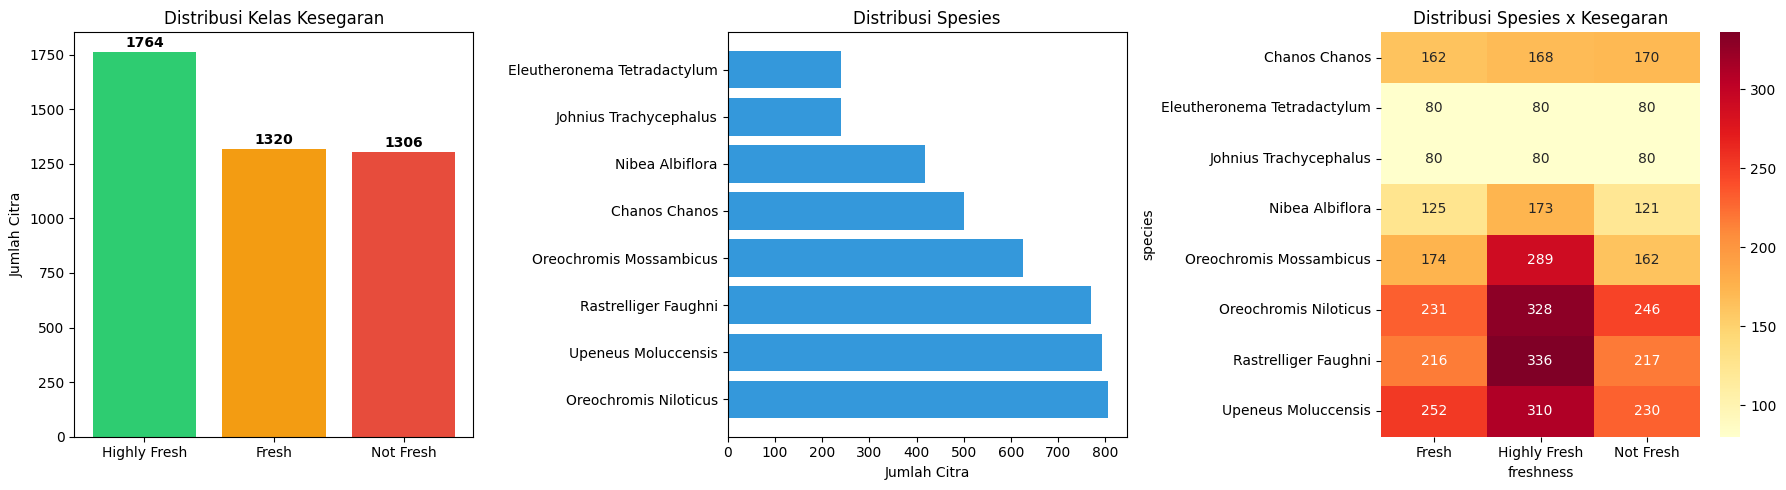

Gambar disimpan ke: /content/drive/MyDrive/tugas_akhir/results/figures/dataset/class_distribution.png


In [8]:
# ============================================================
# SEL 3.1: Distribusi Kelas dan Spesies
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Distribusi kelas kesegaran
class_counts = df['freshness'].value_counts()
axes[0].bar(class_counts.index, class_counts.values,
            color=['#2ecc71', '#f39c12', '#e74c3c'])
axes[0].set_title('Distribusi Kelas Kesegaran', fontsize=12)
axes[0].set_ylabel('Jumlah Citra')
for i, v in enumerate(class_counts.values):
    axes[0].text(i, v + 20, str(v), ha='center', fontweight='bold')

# Plot 2: Distribusi spesies
species_counts = df['species'].value_counts()
axes[1].barh(species_counts.index, species_counts.values, color='#3498db')
axes[1].set_title('Distribusi Spesies', fontsize=12)
axes[1].set_xlabel('Jumlah Citra')

# Plot 3: Heatmap spesies x kesegaran
cross_tab = pd.crosstab(df['species'], df['freshness'])
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd', ax=axes[2])
axes[2].set_title('Distribusi Spesies x Kesegaran', fontsize=12)

plt.tight_layout()

# Simpan ke Drive
save_path = os.path.join(CONFIG['base_drive'], 'results/figures/dataset')
os.makedirs(save_path, exist_ok=True)
plt.savefig(os.path.join(save_path, 'class_distribution.png'),
            dpi=300, bbox_inches='tight')
plt.show()
print(f"Gambar disimpan ke: {save_path}/class_distribution.png")

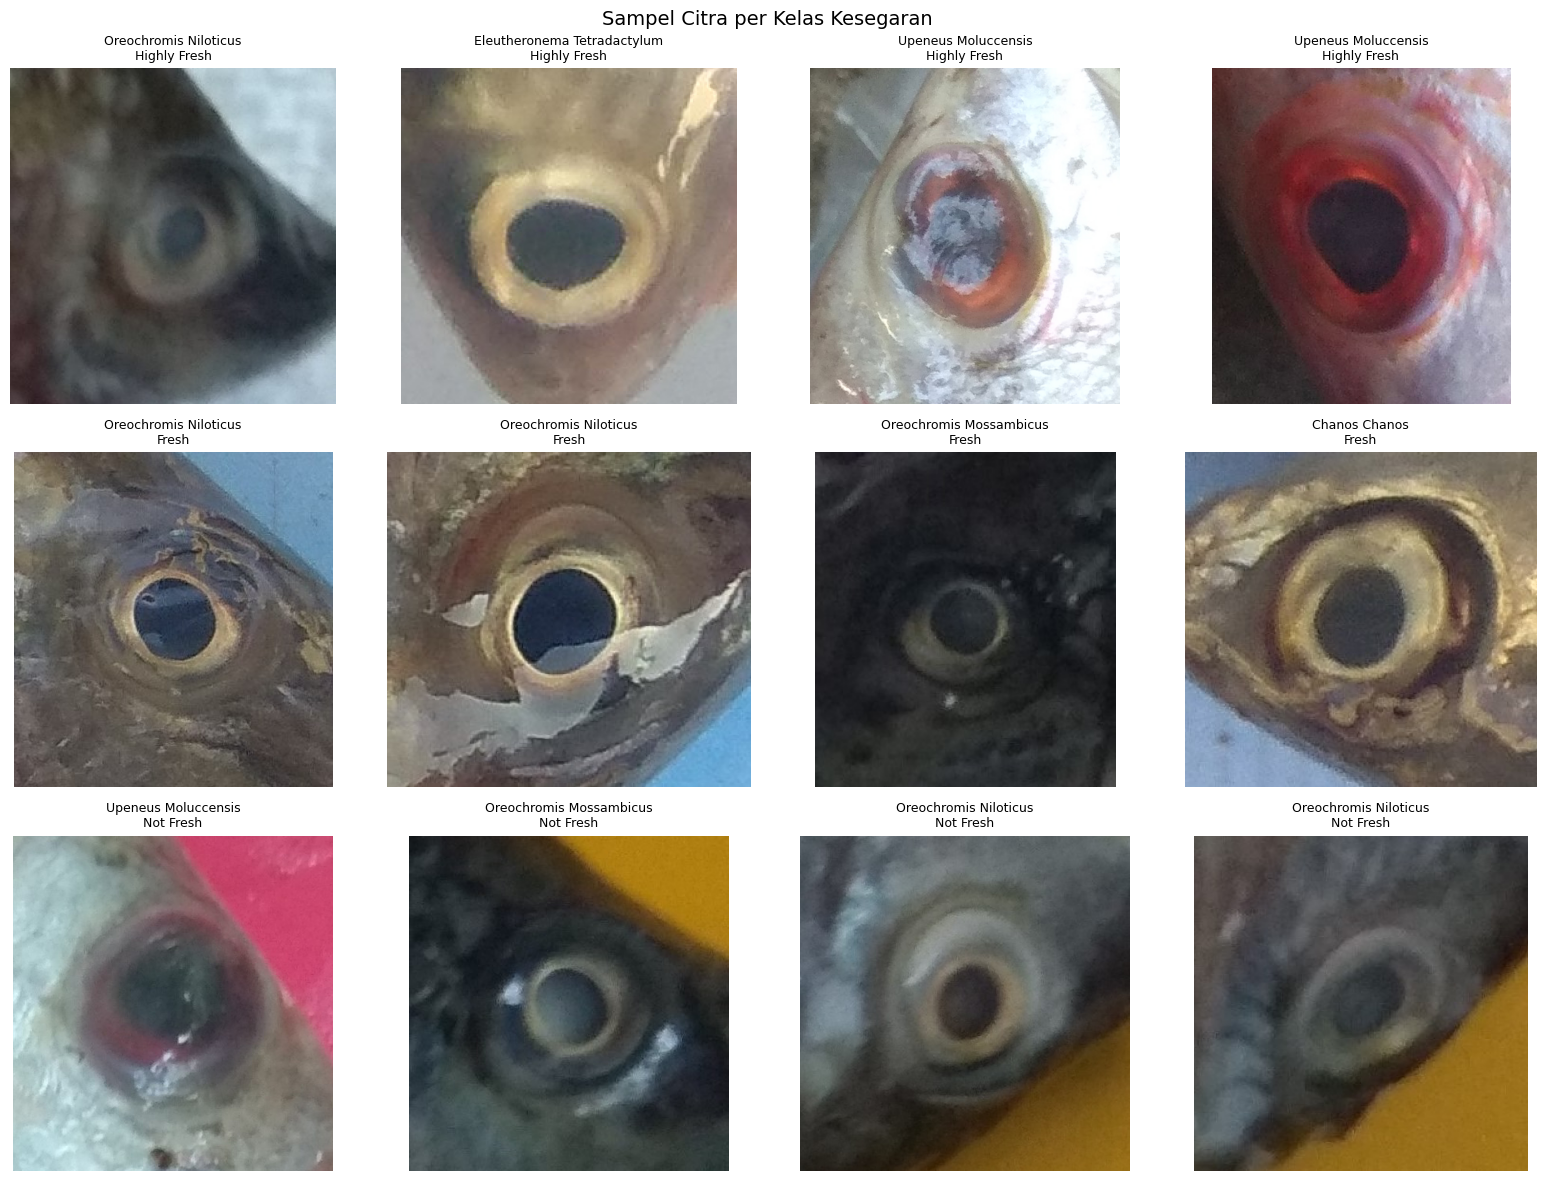

In [9]:
# ============================================================
# SEL 3.2: Visualisasi Sampel per Kelas
# ============================================================
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for row, freshness in enumerate(['Highly Fresh', 'Fresh', 'Not Fresh']):
    samples = df[df['freshness'] == freshness].sample(4, random_state=42)
    for col, (_, sample) in enumerate(samples.iterrows()):
        img = cv2.imread(sample['file_path'])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axes[row, col].imshow(img)
        axes[row, col].set_title(f"{sample['species']}\n{freshness}",
                                 fontsize=9)
        axes[row, col].axis('off')

plt.suptitle('Sampel Citra per Kelas Kesegaran', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(save_path, 'sample_images_per_class.png'),
            dpi=300, bbox_inches='tight')
plt.show()

In [10]:
# ============================================================
# SEL 3.3: Statistik Resolusi Gambar
# ============================================================
heights, widths = [], []
sample_paths = df['file_path'].sample(min(500, len(df)), random_state=42)

for path in tqdm(sample_paths, desc="Memeriksa resolusi gambar"):
    img = cv2.imread(path)
    if img is not None:
        h, w = img.shape[:2]
        heights.append(h)
        widths.append(w)

print(f"Resolusi gambar (sampel {len(heights)} citra):")
print(f"  Tinggi: min={min(heights)}, max={max(heights)}, "
      f"mean={np.mean(heights):.0f}")
print(f"  Lebar:  min={min(widths)}, max={max(widths)}, "
      f"mean={np.mean(widths):.0f}")

Memeriksa resolusi gambar: 100%|██████████| 500/500 [00:00<00:00, 737.16it/s]

Resolusi gambar (sampel 500 citra):
  Tinggi: min=154, max=566, mean=322
  Lebar:  min=167, max=581, mean=325


## **Bagian 4: Pembagian 5-Fold Stratified Cross-Validation**

In [11]:
# ============================================================
# SEL 4.1: Stratified 5-Fold Split
# ============================================================
skf = StratifiedKFold(
    n_splits=CONFIG['n_folds'],
    shuffle=True,
    random_state=CONFIG['random_seed']
)

# Buat kolom fold untuk setiap sampel
df['fold'] = -1
for fold_idx, (train_val_idx, test_idx) in enumerate(
        skf.split(df['file_path'], df['label'])):
    df.loc[test_idx, 'fold'] = fold_idx

# Split train_val menjadi train dan validation (80/20)
for fold_idx in range(CONFIG['n_folds']):
    fold_mask = df['fold'] == fold_idx
    fold_indices = df[fold_mask].index

    # Dari data non-test, ambil 20% untuk validasi
    non_test_mask = df['fold'] != fold_idx
    non_test_indices = df[non_test_mask].index

    # Stratified split untuk validasi
    val_split = StratifiedKFold(n_splits=5, shuffle=True,
                                random_state=CONFIG['random_seed'])
    for tr_idx, val_idx in val_split.split(
            df.loc[non_test_indices, 'file_path'],
            df.loc[non_test_indices, 'label']):
        val_indices = non_test_indices[val_idx]
        df.loc[val_indices, 'subset'] = 'val'
        train_indices = non_test_indices[tr_idx]
        df.loc[train_indices, 'subset'] = 'train'
        break  # Hanya ambil split pertama

    df.loc[fold_mask, 'subset'] = 'test'

# Verifikasi distribusi per fold
print("Distribusi kelas per fold:")
print("=" * 60)
for fold_idx in range(CONFIG['n_folds']):
    fold_df = df[df['fold'] == fold_idx]
    print(f"\nFold {fold_idx + 1} (Test):")
    print(fold_df['freshness'].value_counts().to_string())

    train_val_df = df[df['fold'] != fold_idx]
    train_df = train_val_df[train_val_df['subset'] == 'train']
    val_df = train_val_df[train_val_df['subset'] == 'val']
    print(f"  Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(fold_df)}")

# Simpan metadata pembagian data
df_save_path = os.path.join(CONFIG['base_drive'], 'data/processed')
os.makedirs(df_save_path, exist_ok=True)
df.to_csv(os.path.join(df_save_path, 'dataset_metadata.csv'), index=False)
print(f"\nMetadata disimpan ke: {df_save_path}/dataset_metadata.csv")

Distribusi kelas per fold:

Fold 1 (Test):
freshness
Highly Fresh    353
Fresh           264
Not Fresh       261
  Train: 2145, Val: 489, Test: 878

Fold 2 (Test):
freshness
Highly Fresh    353
Fresh           264
Not Fresh       261
  Train: 2088, Val: 546, Test: 878

Fold 3 (Test):
freshness
Highly Fresh    353
Fresh           264
Not Fresh       261
  Train: 2098, Val: 536, Test: 878

Fold 4 (Test):
freshness
Highly Fresh    353
Fresh           264
Not Fresh       261
  Train: 2096, Val: 538, Test: 878

Fold 5 (Test):
freshness
Highly Fresh    352
Fresh           264
Not Fresh       262
  Train: 2809, Val: 703, Test: 878

Metadata disimpan ke: /content/drive/MyDrive/tugas_akhir/data/processed/dataset_metadata.csv


In [12]:
# ============================================================
# SEL 4.2: Simpan Pembagian Data per Fold (Path File)
# ============================================================
for fold_idx in range(CONFIG['n_folds']):
    fold_dir = os.path.join(CONFIG['base_drive'], f'data/processed/fold_{fold_idx + 1}')
    os.makedirs(fold_dir, exist_ok=True)

    for subset in ['train', 'val', 'test']:
        subset_df = df[(df['fold'] == fold_idx) & (df['subset'] == subset)] \
            if subset == 'test' \
            else df[(df['fold'] != fold_idx) & (df['subset'] == subset)]

        subset_path = os.path.join(fold_dir, f'{subset}_paths.csv')
        subset_df[['file_path', 'label', 'freshness', 'species', 'species_id']].to_csv(
            subset_path, index=False)

    print(f"Fold {fold_idx + 1}: paths tersimpan.")

print("Pembagian data per fold berhasil disimpan.")

Fold 1: paths tersimpan.
Fold 2: paths tersimpan.
Fold 3: paths tersimpan.
Fold 4: paths tersimpan.
Fold 5: paths tersimpan.
Pembagian data per fold berhasil disimpan.


## **Bagian 5: Ekstraksi Fitur Handcrafted (40 Fitur)**

In [13]:
# ============================================================
# SEL 5.1: Definisi Fungsi Ekstraksi Fitur
# ============================================================
def extract_handcrafted_features(image_bgr):
    """
    Mengekstraksi 40 fitur handcrafted dari citra mata ikan.

    Fitur:
    - Color Statistics Lab (12): mean, std, skew, kurt per channel L*, a*, b*
    - CVR a*/b* (1): rasio varians channel a* dan b*
    - Uniform LBP dari b* (10): histogram LBP uniform
    - Hue Histogram (16): histogram hue 16 bins, L2-normalized
    - Sharpness (1): varians Laplacian

    Total: 40 fitur

    Parameters:
        image_bgr: numpy array (H, W, 3), format BGR

    Returns:
        numpy array (40,), vektor fitur
    """
    features = {}

    # Resize ke ukuran standar
    image_bgr = cv2.resize(image_bgr, CONFIG['image_size'])

    # --- 1. Color Statistics Lab (12 fitur) ---
    lab = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2LAB).astype(np.float64)
    for i, ch_name in enumerate(['L', 'a', 'b']):
        ch = lab[:, :, i]
        ch_flat = ch.flatten()
        features[f'{ch_name}_mean'] = np.mean(ch_flat)
        features[f'{ch_name}_std'] = np.std(ch_flat)
        features[f'{ch_name}_skew'] = skew(ch_flat)
        features[f'{ch_name}_kurt'] = kurtosis(ch_flat)

    # --- 2. CVR a*/b* (1 fitur) ---
    a_var = np.var(lab[:, :, 1])
    b_var = np.var(lab[:, :, 2])
    features['cvr_a_b'] = a_var / (b_var + 1e-8)

    # --- 3. Uniform LBP dari b* channel (10 fitur) ---
    b_channel = lab[:, :, 2].astype(np.uint8)
    lbp = local_binary_pattern(b_channel, P=8, R=1, method='uniform')
    hist_lbp, _ = np.histogram(lbp, bins=10, range=(0, 10), density=True)
    for i, h in enumerate(hist_lbp):
        features[f'lbp_{i}'] = h

    # --- 4. Hue Histogram (16 fitur) ---
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    hue_hist = cv2.calcHist([hsv], [0], None, [16], [0, 180]).flatten()
    norm = np.linalg.norm(hue_hist)
    if norm > 0:
        hue_hist = hue_hist / norm  # L2 normalization
    for i, h in enumerate(hue_hist):
        features[f'hue_hist_{i}'] = h

    # --- 5. Sharpness - Laplacian Variance (1 fitur) ---
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    features['sharpness'] = cv2.Laplacian(gray, cv2.CV_64F).var()

    return np.array(list(features.values()), dtype=np.float64)


# Verifikasi jumlah fitur
test_img = cv2.imread(df['file_path'].iloc[0])
test_features = extract_handcrafted_features(test_img)
print(f"Jumlah fitur handcrafted: {len(test_features)}")
print(f"Nama fitur: {list(extract_handcrafted_features.__doc__.split('Fitur:')[0].strip().split('\n')[-1].strip() if False else [])}")

# Tampilkan nama fitur
feature_names = list(features.keys()) if 'features' in dir() else []
test_dict = {}
lab_test = cv2.cvtColor(cv2.resize(test_img, CONFIG['image_size']), cv2.COLOR_BGR2LAB).astype(np.float64)
for i, ch_name in enumerate(['L', 'a', 'b']):
    ch = lab_test[:, :, i].flatten()
    test_dict[f'{ch_name}_mean'] = 0
    test_dict[f'{ch_name}_std'] = 0
    test_dict[f'{ch_name}_skew'] = 0
    test_dict[f'{ch_name}_kurt'] = 0
test_dict['cvr_a_b'] = 0
for i in range(10):
    test_dict[f'lbp_{i}'] = 0
for i in range(16):
    test_dict[f'hue_hist_{i}'] = 0
test_dict['sharpness'] = 0

FEATURE_NAMES = list(test_dict.keys())
print(f"Daftar {len(FEATURE_NAMES)} fitur:")
for i, name in enumerate(FEATURE_NAMES):
    print(f"  {i+1:2d}. {name}")

Jumlah fitur handcrafted: 40
Nama fitur: []
Daftar 40 fitur:
   1. L_mean
   2. L_std
   3. L_skew
   4. L_kurt
   5. a_mean
   6. a_std
   7. a_skew
   8. a_kurt
   9. b_mean
  10. b_std
  11. b_skew
  12. b_kurt
  13. cvr_a_b
  14. lbp_0
  15. lbp_1
  16. lbp_2
  17. lbp_3
  18. lbp_4
  19. lbp_5
  20. lbp_6
  21. lbp_7
  22. lbp_8
  23. lbp_9
  24. hue_hist_0
  25. hue_hist_1
  26. hue_hist_2
  27. hue_hist_3
  28. hue_hist_4
  29. hue_hist_5
  30. hue_hist_6
  31. hue_hist_7
  32. hue_hist_8
  33. hue_hist_9
  34. hue_hist_10
  35. hue_hist_11
  36. hue_hist_12
  37. hue_hist_13
  38. hue_hist_14
  39. hue_hist_15
  40. sharpness


In [14]:
# ============================================================
# SEL 5.2: Ekstraksi Fitur untuk Seluruh Dataset
# ============================================================
# Ekstraksi fitur untuk semua citra
all_features = []
all_labels = []
all_paths = []
failed_images = []

print(f"Mengekstraksi fitur untuk {len(df)} citra...")
print("Estimasi waktu: 10-20 menit")

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Ekstraksi fitur"):
    try:
        img = cv2.imread(row['file_path'])
        if img is None:
            failed_images.append(row['file_path'])
            continue

        feat = extract_handcrafted_features(img)

        # Cek NaN atau Inf
        if np.any(np.isnan(feat)) or np.any(np.isinf(feat)):
            feat = np.nan_to_num(feat, nan=0.0, posinf=1e6, neginf=-1e6)

        all_features.append(feat)
        all_labels.append(row['label'])
        all_paths.append(row['file_path'])

    except Exception as e:
        failed_images.append(row['file_path'])
        if len(failed_images) <= 5:
            print(f"  Error pada {row['filename']}: {e}")

# Konversi ke numpy array
X_all = np.array(all_features, dtype=np.float64)
y_all = np.array(all_labels, dtype=np.int64)
paths_all = np.array(all_paths)

print(f"\nEkstraksi selesai.")
print(f"  Berhasil: {len(X_all)} citra")
print(f"  Gagal: {len(failed_images)} citra")
if failed_images:
    print(f"  File gagal: {failed_images[:5]}")
print(f"  Shape fitur: {X_all.shape}")

Mengekstraksi fitur untuk 4390 citra...
Estimasi waktu: 10-20 menit


Ekstraksi fitur: 100%|██████████| 4390/4390 [02:22<00:00, 30.88it/s]


Ekstraksi selesai.
  Berhasil: 4390 citra
  Gagal: 0 citra
  Shape fitur: (4390, 40)


In [15]:
# ============================================================
# SEL 5.3: Simpan Fitur Lengkap ke Drive
# ============================================================
features_dir = os.path.join(CONFIG['base_drive'], 'data/features/handcrafted')
os.makedirs(features_dir, exist_ok=True)

# Simpan seluruh fitur (untuk backup)
np.save(os.path.join(features_dir, 'all_features.npy'), X_all)
np.save(os.path.join(features_dir, 'all_labels.npy'), y_all)
np.save(os.path.join(features_dir, 'all_paths.npy'), paths_all)

# Simpan nama fitur
with open(os.path.join(features_dir, 'feature_names.pkl'), 'wb') as f:
    pickle.dump(FEATURE_NAMES, f)

print(f"Fitur lengkap disimpan ke: {features_dir}")
print(f"  all_features.npy: shape {X_all.shape}")
print(f"  all_labels.npy: shape {y_all.shape}")

Fitur lengkap disimpan ke: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted
  all_features.npy: shape (4390, 40)
  all_labels.npy: shape (4390,)


## **Bagian 6: Simpan Fitur per Fold dengan Normalisasi**

In [16]:
# ============================================================
# SEL 6.1: Simpan Fitur per Fold dengan StandardScaler
# ============================================================
# Buat mapping path -> index fitur
path_to_idx = {p: i for i, p in enumerate(paths_all)}

scalers_dir = os.path.join(CONFIG['base_drive'], 'data/scalers')
os.makedirs(scalers_dir, exist_ok=True)

for fold_idx in range(CONFIG['n_folds']):
    fold_num = fold_idx + 1
    print(f"\n--- Fold {fold_num} ---")

    # Dapatkan indices untuk setiap subset
    test_mask = df['fold'] == fold_idx
    train_mask = (df['fold'] != fold_idx) & (df['subset'] == 'train')
    val_mask = (df['fold'] != fold_idx) & (df['subset'] == 'val')

    def get_indices(mask):
        indices = []
        for _, row in df[mask].iterrows():
            if row['file_path'] in path_to_idx:
                indices.append(path_to_idx[row['file_path']])
        return indices

    train_idx = get_indices(train_mask)
    val_idx = get_indices(val_mask)
    test_idx = get_indices(test_mask)

    X_train = X_all[train_idx]
    X_val = X_all[val_idx]
    X_test = X_all[test_idx]

    y_train = y_all[train_idx]
    y_val = y_all[val_idx]
    y_test = y_all[test_idx]

    print(f"  Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

    # PENTING: Fit StandardScaler HANYA pada data training
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # Simpan fitur ternormalisasi per fold
    fold_feat_dir = os.path.join(features_dir, f'fold_{fold_num}')
    os.makedirs(fold_feat_dir, exist_ok=True)

    np.save(os.path.join(fold_feat_dir, 'train_hand.npy'), X_train_scaled)
    np.save(os.path.join(fold_feat_dir, 'val_hand.npy'), X_val_scaled)
    np.save(os.path.join(fold_feat_dir, 'test_hand.npy'), X_test_scaled)

    np.save(os.path.join(fold_feat_dir, 'train_labels.npy'), y_train)
    np.save(os.path.join(fold_feat_dir, 'val_labels.npy'), y_val)
    np.save(os.path.join(fold_feat_dir, 'test_labels.npy'), y_test)

    # Simpan scaler per fold
    scaler_path = os.path.join(scalers_dir, f'fold_{fold_num}_scaler.pkl')
    with open(scaler_path, 'wb') as f:
        pickle.dump(scaler, f)

    print(f"  Fitur dan scaler Fold {fold_num} tersimpan.")

print("\nSeluruh fitur per fold berhasil disimpan.")


--- Fold 1 ---
  Train: (2145, 40), Val: (489, 40), Test: (878, 40)
  Fitur dan scaler Fold 1 tersimpan.

--- Fold 2 ---
  Train: (2088, 40), Val: (546, 40), Test: (878, 40)
  Fitur dan scaler Fold 2 tersimpan.

--- Fold 3 ---
  Train: (2098, 40), Val: (536, 40), Test: (878, 40)
  Fitur dan scaler Fold 3 tersimpan.

--- Fold 4 ---
  Train: (2096, 40), Val: (538, 40), Test: (878, 40)
  Fitur dan scaler Fold 4 tersimpan.

--- Fold 5 ---
  Train: (2809, 40), Val: (703, 40), Test: (878, 40)
  Fitur dan scaler Fold 5 tersimpan.

Seluruh fitur per fold berhasil disimpan.


## **Bagian 7: Verifikasi Output**

In [17]:
# ============================================================
# SEL 7.1: Verifikasi Seluruh Output
# ============================================================
print("=" * 70)
print("VERIFIKASI OUTPUT NOTEBOOK 1")
print("=" * 70)

BASE = CONFIG['base_drive']

# Cek metadata
metadata_path = os.path.join(BASE, 'data/processed/dataset_metadata.csv')
if os.path.exists(metadata_path):
    df_check = pd.read_csv(metadata_path)
    print(f"\n[OK] Metadata: {metadata_path}")
    print(f"     Total citra: {len(df_check)}")
    print(f"     Kolom: {list(df_check.columns)}")
else:
    print(f"\n[FAIL] Metadata tidak ditemukan: {metadata_path}")

# Cek fitur per fold
print(f"\nFitur per fold:")
for fold_num in range(1, 6):
    fold_dir = os.path.join(BASE, f'data/features/handcrafted/fold_{fold_num}')
    files = ['train_hand.npy', 'val_hand.npy', 'test_hand.npy',
             'train_labels.npy', 'val_labels.npy', 'test_labels.npy']
    all_exist = all(os.path.exists(os.path.join(fold_dir, f)) for f in files)
    status = "OK" if all_exist else "FAIL"
    print(f"  [{status}] Fold {fold_num}: {fold_dir}")

    if all_exist:
        X_tr = np.load(os.path.join(fold_dir, 'train_hand.npy'))
        print(f"         train_hand.npy shape: {X_tr.shape}")

# Cek scaler
print(f"\nScaler per fold:")
for fold_num in range(1, 6):
    scaler_path = os.path.join(BASE, f'data/scalers/fold_{fold_num}_scaler.pkl')
    status = "OK" if os.path.exists(scaler_path) else "FAIL"
    print(f"  [{status}] {scaler_path}")

# Cek gambar EDA
print(f"\nGambar EDA:")
for fig_name in ['class_distribution.png', 'sample_images_per_class.png']:
    fig_path = os.path.join(BASE, f'results/figures/dataset/{fig_name}')
    status = "OK" if os.path.exists(fig_path) else "FAIL"
    print(f"  [{status}] {fig_name}")

# Cek feature names
fn_path = os.path.join(BASE, 'data/features/handcrafted/feature_names.pkl')
if os.path.exists(fn_path):
    with open(fn_path, 'rb') as f:
        fn_check = pickle.load(f)
    print(f"\n[OK] Feature names: {len(fn_check)} fitur")
else:
    print(f"\n[FAIL] Feature names tidak ditemukan")

print("\n" + "=" * 70)
print("NOTEBOOK 1 SELESAI")
print("=" * 70)

VERIFIKASI OUTPUT NOTEBOOK 1

[OK] Metadata: /content/drive/MyDrive/tugas_akhir/data/processed/dataset_metadata.csv
     Total citra: 4390
     Kolom: ['file_path', 'folder', 'species', 'freshness', 'filename', 'label', 'species_id', 'fold', 'subset']

Fitur per fold:
  [OK] Fold 1: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted/fold_1
         train_hand.npy shape: (2145, 40)
  [OK] Fold 2: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted/fold_2
         train_hand.npy shape: (2088, 40)
  [OK] Fold 3: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted/fold_3
         train_hand.npy shape: (2098, 40)
  [OK] Fold 4: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted/fold_4
         train_hand.npy shape: (2096, 40)
  [OK] Fold 5: /content/drive/MyDrive/tugas_akhir/data/features/handcrafted/fold_5
         train_hand.npy shape: (2809, 40)

Scaler per fold:
  [OK] /content/drive/MyDrive/tugas_akhir/data/scalers/fold_1_scaler.pkl
  [OK] /content

In [18]:
# ============================================================
# SEL 7.2: Ringkasan untuk Bab 3 dan Bab 4 Skripsi
# ============================================================
print("=" * 70)
print("RINGKASAN UNTUK SKRIPSI")
print("=" * 70)

print(f"""
Dataset:
  - Nama: Freshness of Fish Eyes (FFE)
  - Total citra: {len(df)}
  - Resolusi asli: bervariasi, di-resize ke 224x224
  - Kelas: 3 (Highly Fresh, Fresh, Not Fresh)
  - Spesies: {df['species'].nunique()}
  - Distribusi kelas:
    * Highly Fresh: {len(df[df['label']==0])} citra
    * Fresh: {len(df[df['label']==1])} citra
    * Not Fresh: {len(df[df['label']==2])} citra

Pembagian Data:
  - Metode: Stratified 5-Fold Cross-Validation
  - Random seed: {CONFIG['random_seed']}
  - Per fold: ~80% train, ~20% val (dari non-test), 20% test

Fitur Handcrafted:
  - Jumlah: {len(FEATURE_NAMES)} fitur
  - Komponen:
    * Color Statistics Lab: 12 fitur (mean, std, skew, kurt per channel)
    * CVR a*/b*: 1 fitur
    * Uniform LBP (b* channel): 10 fitur
    * Hue Histogram: 16 fitur (L2-normalized)
    * Sharpness (Laplacian variance): 1 fitur

Normalisasi:
  - Metode: StandardScaler (z-score)
  - Fit HANYA pada data training per fold (mencegah data leakage)
""")

RINGKASAN UNTUK SKRIPSI

Dataset:
  - Nama: Freshness of Fish Eyes (FFE)
  - Total citra: 4390
  - Resolusi asli: bervariasi, di-resize ke 224x224
  - Kelas: 3 (Highly Fresh, Fresh, Not Fresh)
  - Spesies: 8
  - Distribusi kelas:
    * Highly Fresh: 1764 citra
    * Fresh: 1320 citra
    * Not Fresh: 1306 citra

Pembagian Data:
  - Metode: Stratified 5-Fold Cross-Validation
  - Random seed: 42
  - Per fold: ~80% train, ~20% val (dari non-test), 20% test

Fitur Handcrafted:
  - Jumlah: 40 fitur
  - Komponen:
    * Color Statistics Lab: 12 fitur (mean, std, skew, kurt per channel)
    * CVR a*/b*: 1 fitur
    * Uniform LBP (b* channel): 10 fitur
    * Hue Histogram: 16 fitur (L2-normalized)
    * Sharpness (Laplacian variance): 1 fitur

Normalisasi:
  - Metode: StandardScaler (z-score)
  - Fit HANYA pada data training per fold (mencegah data leakage)



## **Perbaikan**

In [19]:
# ============================================================
# SEL PERBAIKAN: Pembagian Train/Val per Fold yang Benar
# ============================================================
import os, pickle
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

BASE = '/content/drive/MyDrive/tugas_akhir'
meta = pd.read_csv(f'{BASE}/data/processed/dataset_metadata.csv')

# Hapus kolom subset global yang keliru
if 'subset' in meta.columns:
    meta = meta.drop(columns=['subset'])

hand_dir = f'{BASE}/data/features/handcrafted'
X_all   = np.load(f'{hand_dir}/all_features.npy')
y_all   = np.load(f'{hand_dir}/all_labels.npy')
paths_all = np.load(f'{hand_dir}/all_paths.npy')
path_to_idx = {p: i for i, p in enumerate(paths_all)}

# Outer split: parameter IDENTIK dengan sebelumnya agar test-set tidak berubah
skf_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (tr_val_idx, test_idx) in enumerate(
        skf_outer.split(meta['file_path'], meta['label'])):

    # Inner split 80/20 HANYA pada sampel non-test fold ini
    inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    inner_tr, inner_val = next(iter(inner.split(
        meta['file_path'].iloc[tr_val_idx], meta['label'].iloc[tr_val_idx])))
    train_idx = tr_val_idx[inner_tr]
    val_idx   = tr_val_idx[inner_val]

    # Tulis ulang CSV paths per fold
    fold_dir = f'{BASE}/data/processed/fold_{fold_idx + 1}'
    cols = ['file_path', 'label', 'freshness', 'species', 'species_id']
    for name, idx in [('train', train_idx), ('val', val_idx), ('test', test_idx)]:
        meta.iloc[idx][cols].to_csv(f'{fold_dir}/{name}_paths.csv', index=False)

    # Potong ulang fitur dan refit scaler pada train yang benar
    def slice_feats(idx):
        rows = [path_to_idx[p] for p in meta['file_path'].iloc[idx]]
        return X_all[rows], y_all[rows]

    X_tr, y_tr = slice_feats(train_idx)
    X_va, y_va = slice_feats(val_idx)
    X_te, y_te = slice_feats(test_idx)

    scaler = StandardScaler().fit(X_tr)
    fd = f'{hand_dir}/fold_{fold_idx + 1}'
    np.save(f'{fd}/train_hand.npy', scaler.transform(X_tr))
    np.save(f'{fd}/val_hand.npy',   scaler.transform(X_va))
    np.save(f'{fd}/test_hand.npy',  scaler.transform(X_te))
    np.save(f'{fd}/train_labels.npy', y_tr)
    np.save(f'{fd}/val_labels.npy',   y_va)
    np.save(f'{fd}/test_labels.npy',  y_te)
    with open(f'{BASE}/data/scalers/fold_{fold_idx + 1}_scaler.pkl', 'wb') as f:
        pickle.dump(scaler, f)

    print(f'Fold {fold_idx + 1}: train={len(train_idx)}, '
          f'val={len(val_idx)}, test={len(test_idx)}')

# Perbarui metadata (kolom fold tetap, kolom subset dihapus)
meta.to_csv(f'{BASE}/data/processed/dataset_metadata.csv', index=False)
print('\nPerbaikan selesai. Seluruh artefak per fold telah diregenerasi.')

Fold 1: train=2809, val=703, test=878
Fold 2: train=2809, val=703, test=878
Fold 3: train=2809, val=703, test=878
Fold 4: train=2809, val=703, test=878
Fold 5: train=2809, val=703, test=878

Perbaikan selesai. Seluruh artefak per fold telah diregenerasi.
